# Lab 4-01：用 LLM 把文字拆成三元組

**目標**：從 34 段海賊王劇情摘要裡挑 7 段，交給本地小模型抽成 (主體, 關係, 客體) 三元組，
量出它抽得多準、錯在哪，再用正規化把名字對齊；最後載入整份人工校對過的三元組，存成 `data/triples.json` 給後面三本用。

**你會學到**
- 不給規格，模型每次發明不同的關係名稱
- 用 Pydantic 定義「只能用這 8 種關係」，再交給模型做受限輸出
- 用標準答案量 precision／recall，知道錯在哪
- 實體正規化：同一個人的不同叫法要合併，否則圖會裂成孤島；但名字像的不一定是同一個東西
- 真實專案怎麼做：離線批次抽取＋人工校對，而不是在 notebook 裡即時抽全量

**前置**：先讀 `00_concepts.md`（三元組、實體正規化）。模組 3 的 embedding 概念；Ollama 已有 `qwen2.5:3b` 與 `bge-m3`。全部跑完約 5～10 分鐘，大多花在模型推論。

**對應投影片**：「實體、關係、屬性」「LLM 抽取三元組」「Lab 4 圖譜長相」「踩坑：別名、成本、語法」

![LLM 抽取三元組的流程](images/extract_triples.jpg)

*圖：由左往右讀。段落交給 LLM，Pydantic 規格限制它能輸出的格式；抽出的三元組先經過驗證與正規化（別名表在這裡合併稱呼），錯的丟掉，對的才存進 triples.json。*

## Step 1：讀語料

語料是課程自己寫的摘要（`data/one_piece_summaries.md`），34 段、約三萬多個 token。為了模擬真實文件，
同一個人在不同段落會用不同稱呼：「魯夫」「蒙其·D·魯夫」「草帽小子」都是同一個人；
也刻意埋了幾個**名字很像、其實不同**的陷阱，等一下正規化時會遇到。

In [1]:
import json
import re
import time
from pathlib import Path

text = Path("data/one_piece_summaries.md").read_text(encoding="utf-8")

paragraphs = []
for block in re.split(r"^## ", text, flags=re.M)[1:]:
    head, _, body = block.partition("\n")
    pid, title = head.split(maxsplit=1)
    paragraphs.append({"id": pid, "title": title, "text": body.strip()})

print("段落數：", len(paragraphs), "，平均每段", sum(len(p["text"]) for p in paragraphs) // len(paragraphs), "字")
for p in paragraphs[:3]:
    print(f"[{p['id']}] {p['title']}：{p['text'][:80]}…")

段落數： 34 ，平均每段 1143 字
[01] 風車村的少年：魯夫出身東海的風車村。那是一個面海的小村子，山坡上立著幾座風車，村民大多靠捕魚和種田過日子。他小時候誤吃了橡膠果實，身體從此能像橡皮一樣伸長，代價是再也不會游泳…
[02] 紅髮與草帽：香克斯是紅髮海賊團的船長，曾帶著船員在風車村住了一段時間。他有一頭醒目的紅髮，愛喝酒、愛說笑，看起來一點也不像傳聞中可怕的海賊。紅髮海賊團把風車村當作停靠的據點…
[03] 出海：十七歲那年，蒙其·D·魯夫戴著那頂草帽，獨自划小船出海，成立了草帽海賊團並擔任船長。他的夢想是成為海賊王。那時距離紅髮海賊團離開風車村已經過了十年，村民在港口送…


## Step 2：先不給規格，看它怎麼抽

最直覺的做法：叫模型「列出三元組」。挑兩段試試，注意關係欄位寫了什麼。

In [2]:
import os

from openai import OpenAI

# 抽取的輸入輸出都長，直接用 OpenAI SDK 連 Ollama，給比 course_utils 長的逾時（300 秒）
client = OpenAI(base_url=os.getenv("LOCAL_BASE_URL", "http://localhost:11434/v1"), api_key="ollama", timeout=300)
MODEL = os.getenv("LOCAL_MODEL", "qwen2.5:3b")


def chat(messages: list[dict], temperature: float = 0, **kwargs) -> str:
    resp = client.chat.completions.create(model=MODEL, messages=messages, temperature=temperature, **kwargs)
    return resp.choices[0].message.content


NAIVE = "從下面的文字抽出知識圖譜的三元組，每行一個，格式：(主體, 關係, 客體)。"

for p in paragraphs[2:4]:
    print(f"--- 段落 {p['id']}")
    print(chat([{"role": "user", "content": NAIVE + "\n\n" + p["text"]}], max_tokens=400))  # 不設上限它會一直列下去

--- 段落 03
(蒙其·D·魯夫, 成立, 草帽海賊團)
(蒙其·D·魯夫, 擔任, 船長)
(海賊王, 是, 哥爾·D·羅傑)
(One Piece, 是, 哥爾·D·羅傑的財寶)
(亞爾薇達, 是, 女海賊)
(亞爾薇達, 抓, 科比)
(蒙卡上校, 仗著權力欺壓, 鎮民)
(蒙卡上校, 被, 草帽少年打倒)
(科比, 成為, 海軍大將)
(科比, 加入, 海軍)
(蒙其·D·魯夫, 與, 科比約定)
(蒙其·D·魯夫, 往東航行, 寻找)
(蒙其·D·魯夫, 往東航行, 寻找航海士)
(蒙其·D·魯夫, 往東航行, 寻找廚師)
(蒙其·D·魯夫, 往東航行，尋找音樂家)
(蒙其·D·魯夫, 往東航行, 寻找偉大航道的入口)
(顛倒山, 是, 偉大航道的入口)
(顛倒山, 在, 海流的推動下)
(顛倒山, 在, 山壁的上方)
(顛倒山, 在, 山壁的下方)
(顛倒山, 在, 海流的推動下)
(顛倒山, 在, 海流的推動下)
(顛倒山, 在, 海流的推動下)
(顛倒山, 在, 海流的推動下
--- 段落 04
(羅羅亞·索隆, 使用, 三把刀的三刀流)
(羅羅亞·索隆, 梦想, 成為世界第一大劍豪)
(羅羅亞·索隆, 稍微, 綠色短髮)
(羅羅亞·索隆, 左耳, 左耳戴著三個金耳環)
(羅羅亞·索隆, 左手臂上, 常綁著一條黑色頭巾)
(羅羅亞·索隆, 梦想, 完成自己的夢想)
(羅羅亞·索隆, 船長, 在海軍基地的廣場上認識)
(羅羅亞·索隆, 與, 贝魯梅伯)
(羅羅亞·索隆, 與, 蒙卡上校)
(羅羅亞·索隆, 與, 科比)
(羅羅亞·索隆, 與, 貝魯梅伯)
(羅羅亞·索隆, 與, 小丑巴其的海賊團)
(羅羅亞·索隆, 與, 船長)
(羅羅亞·索隆, 與, 阿拉巴斯坦的殺手)
(羅羅亞·索隆, 與, 司法之島的狙擊手)
(羅羅亞·索隆, 與, 司法之島的手銬)
(羅羅亞·索隆, 與, 司法之島的刀刃)
(羅羅亞·索隆, 與, 司法之島的鋼鐵)
(羅羅亞·索隆, 與, 司法之島的船長)
(羅羅亞·索隆, 與


能讀，但沒法用：同一種關係，這段寫「是船長」，那段寫「擔任」「為…的船長」；
客體有時是名字，有時是一整句話。圖資料庫裡每一種寫法都會變成不同的邊，查詢時根本對不起來。

解法跟模組 2 的結構化輸出一樣：**先定規格，再叫模型照規格填**。
把「開放式生成」變成「從固定類別裡挑」，錯得比較少。

## Step 3：用 Pydantic 定規格

我們只允許 8 種關係。每種關係的主體與客體類型是固定的（投影片「Lab 4 圖譜長相」的擴充版）：

```
(:Person)-[:CAPTAIN_OF | MEMBER_OF]->(:Crew)
(:Person)-[:OWNS]->(:Treasure)
(:Person)-[:DREAMS_OF]->(:Dream)
(:Person)-[:FROM]->(:Place)
(:Person)-[:HAS_FATHER | BROTHER_OF | DEFEATED]->(:Person)
```

In [3]:
from typing import Literal

from pydantic import BaseModel, ValidationError

Relation = Literal[
    "CAPTAIN_OF", "MEMBER_OF", "OWNS", "DREAMS_OF",
    "FROM", "HAS_FATHER", "BROTHER_OF", "DEFEATED",
]


class Triple(BaseModel):
    subject: str
    relation: Relation
    object: str


class Extraction(BaseModel):
    triples: list[Triple]


schema = Extraction.model_json_schema()
print(json.dumps(schema["$defs"]["Triple"]["properties"]["relation"], ensure_ascii=False))

{"enum": ["CAPTAIN_OF", "MEMBER_OF", "OWNS", "DREAMS_OF", "FROM", "HAS_FATHER", "BROTHER_OF", "DEFEATED"], "title": "Relation", "type": "string"}


`relation` 只能是那 8 個字串之一。這份 JSON Schema 會直接交給 Ollama 當「受限輸出」的格式：
模型在生成時就只能吐出符合 schema 的 JSON，不只是事後檢查。

再寫一份 prompt，把每種關係的線索、規則與一個範例講清楚。範例刻意用虛構人物，免得模型直接抄答案。

In [4]:
SYSTEM = """你是知識圖譜抽取器。從一段文字抽出 (主體, 關係, 客體) 三元組。只准用這 8 種關係：

| 關係 | 主體 | 客體 | 文字裡的線索 |
|---|---|---|---|
| CAPTAIN_OF | 人物 | 海賊團 | 「…的船長」「帶頭」 |
| MEMBER_OF | 人物 | 海賊團 | 「是…的劍士／航海士／成員」 |
| OWNS | 人物 | 物品 | 「吃了…果實」「擁有」「保管」 |
| DREAMS_OF | 人物 | 目標 | 「夢想是…」 |
| FROM | 人物 | 地方 | 「出身…」 |
| HAS_FATHER | 人物 | 人物 | 「X 的父親是 Y」→ (X, HAS_FATHER, Y) |
| BROTHER_OF | 人物 | 人物 | 「哥哥」「結拜兄弟」 |
| DEFEATED | 人物 | 人物 | 「打倒」「打敗」 |

規則：
1. 主體、客體都要是文字裡出現的名字，寫最短的叫法（「魯夫」，不要「十七歲的魯夫」）。
2. 「他」「她」要換成前面提到的名字；換不出來就整條不要。
3. 文字沒有線索的關係就不要輸出，寧可少不要錯；不准寫「某人」「未知」。
4. 只輸出 JSON。

範例文字：小明是藍鯨海賊團的船長，出身南島。他吃了泡泡果實，夢想是環遊世界。他的妹妹小華是藍鯨海賊團的廚師。
範例輸出：{"triples": [{"subject": "小明", "relation": "CAPTAIN_OF", "object": "藍鯨海賊團"}, {"subject": "小明", "relation": "FROM", "object": "南島"}, {"subject": "小明", "relation": "OWNS", "object": "泡泡果實"}, {"subject": "小明", "relation": "DREAMS_OF", "object": "環遊世界"}, {"subject": "小華", "relation": "MEMBER_OF", "object": "藍鯨海賊團"}]}"""

RESPONSE_FORMAT = {"type": "json_schema", "json_schema": {"name": "extraction", "schema": schema}}

## Step 4：抽一段看看

挑第 18 段「結拜兄弟」：一段裡有兄弟、父親、果實、海賊團好幾種關係。

In [5]:
from openai import OpenAIError


def extract(paragraph: str) -> list[dict]:
    """抽一段；小模型偶爾會卡在重複輸出而被 Ollama 中止，就稍微提高溫度重試一次。"""
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": "文字：" + paragraph}]
    for temperature in (0.0, 0.3):
        try:
            raw = chat(messages, temperature=temperature, response_format=RESPONSE_FORMAT, max_tokens=900)
            return [t.model_dump() for t in Extraction.model_validate_json(raw).triples]
        except (OpenAIError, ValidationError) as exc:
            print(f"  （重試：{type(exc).__name__}）")
    return []


by_id = {p["id"]: p for p in paragraphs}
cache = {}  # 抽過的段落存起來，Step 5 不重抽

t0 = time.time()
cache["18"] = extract(by_id["18"]["text"])
print(f"花了 {time.time() - t0:.0f} 秒")
for t in cache["18"]:
    print(t)

花了 3 秒
{'subject': '魯夫', 'relation': 'BROTHER_OF', 'object': '薩波'}
{'subject': '魯夫', 'relation': 'BROTHER_OF', 'object': '艾斯'}
{'subject': '艾斯', 'relation': 'OWNS', 'object': '燒燒果實'}
{'subject': '艾斯', 'relation': 'HAS_FATHER', 'object': '羅傑'}
{'subject': '艾斯', 'relation': 'HAS_FATHER', 'object': '露玖'}
{'subject': '艾斯', 'relation': 'DREAMS_OF', 'object': '成為海賊王'}


## Step 5：抽一個子集

3B 模型在筆電上抽一段要十幾秒到一分鐘，34 段全抽會花掉整堂課。課堂上只抽 7 段當示範：
前面幾段（主角群出場）加上兩段埋了陷阱的：第 20 段（草帽大船團，七個海賊團的船長一口氣出場）、第 32 段（和之國，好幾顆名字很長的果實）。

真實專案的做法是**離線批次抽取**：晚上把全部文件丟給比較大的模型平行跑，隔天再抽樣人工校對。notebook 裡只示範流程。

In [6]:
SUBSET = ["01", "03", "04", "06", "18", "20", "32"]

start = time.time()
raw_triples = []
for pid in SUBSET:
    if pid not in cache:
        cache[pid] = extract(by_id[pid]["text"])
    raw_triples += [{**t, "paragraph": pid} for t in cache[pid]]
    print(f"[{pid}] {by_id[pid]['title']}：{len(cache[pid])} 條")
print(f"共 {len(raw_triples)} 條，花了 {time.time() - start:.0f} 秒")

[01] 風車村的少年：5 條
[03] 出海：6 條
[04] 第一位同伴：8 條
[06] 海賊獵人：5 條
[18] 結拜兄弟：6 條
[20] 草帽大船團：12 條
  （重試：ValidationError）
  （重試：ValidationError）
[32] 和之國：0 條
共 42 條，花了 51 秒


In [7]:
for t in raw_triples:
    print(t["paragraph"], t["subject"], t["relation"], t["object"])

01 魯夫 FROM 東海
01 魯夫 MEMBER_OF 風車村
01 魯夫 HAS_FATHER 蒙其·D·多拉格
01 魯夫 CAPTAIN_OF 風車村
01 魯夫 DREAMS_OF 揚帆出海
03 魯夫 CAPTAIN_OF 草帽海賊團
03 魯夫 DREAMS_OF 成為海賊王
03 亞爾薇達 MEMBER_OF 海賊
03 科比 MEMBER_OF 海賊
03 科比 MEMBER_OF 海軍
03 蒙卡 DEFEATED 少年船長
04 羅羅亞·索隆 CAPTAIN_OF 草帽海賊團
04 羅羅亞·索隆 FROM 南島
04 羅羅亞·索隆 DREAMS_OF 成為世界第一大劍豪
04 羅羅亞·索隆 HAS_FATHER 未知
04 羅羅亞·索隆 MEMBER_OF 草帽海賊團
04 羅羅亞·索隆 BROTHER_OF 未知
04 羅羅亞·索隆 DEFEATED 蒙卡上校
04 羅羅亞·索隆 DEFEATED 小丑巴其的海賊團
06 索隆 FROM 霜月村
06 索隆 OWNS 白鞘刀
06 索隆 DREAMS_OF 世界第一的劍士
06 索隆 HAS_FATHER 未知
06 約瑟夫 BROTHER_OF 強尼
18 魯夫 BROTHER_OF 薩波
18 魯夫 BROTHER_OF 艾斯
18 艾斯 OWNS 燒燒果實
18 艾斯 HAS_FATHER 羅傑
18 艾斯 HAS_FATHER 露玖
18 艾斯 DREAMS_OF 成為海賊王
20 魯夫 CAPTAIN_OF 草帽大船團
20 魯夫 HAS_FATHER 艾斯
20 魯夫 HAS_FATHER 薩波
20 海爾丁 CAPTAIN_OF 新巨兵海賊團
20 海爾丁 FROM 艾爾巴夫
20 凱文迪許 CAPTAIN_OF 美麗海賊團
20 齊 CAPTAIN_OF 八寶水軍
20 伊迪歐 CAPTAIN_OF XXX健身武鬥會
20 頓塔塔海賊團 CAPTAIN_OF 雷歐
20 約塔瑪麗亞大船團 CAPTAIN_OF 歐倫波斯
20 巴托俱樂部 CAPTAIN_OF 巴托洛米奧
20 約塔瑪麗亞大船團 HAS_FATHER 艾爾巴夫


先自己掃一遍，你大概會看到這幾種錯（每次跑不完全一樣，下面是存檔那次看到的）：

- **方向反了**：(頓塔塔海賊團, CAPTAIN_OF, 雷歐)，主體客體對調。
- **關係標錯**：兄弟被標成 `HAS_FATHER`（魯夫的「父親」是艾斯）；船員被標成 `CAPTAIN_OF`。
- **不聽話**：規則明說不准寫「未知」，它還是寫了；也會把「海賊」「海軍」這種泛稱當成海賊團。
- **抄範例**：(羅羅亞·索隆, FROM, 南島)——「南島」是 prompt 範例裡虛構人物的故鄉，原文根本沒有。
- **同一個人多個名字**：「羅羅亞·索隆」和「索隆」各自成了一個節點；偶爾還會把「海賊團」寫錯字。
- **長名字被拆開**（較早一次執行看到的；存檔這次第 32 段兩次都沒通過格式驗證，抽到 0 條）：第 32 段的「人人果實．幻獸種．模型『尼卡』」被拆成「人人果實」「幻獸種」「模型『尼卡』」三樣寶物。
  其中 (魯夫, OWNS, 人人果實) 看起來對，其實剛好變成了喬巴的果實。

受限輸出只保證**格式**對（JSON、關係名稱在清單內），不保證**內容**對。

用眼睛看只能抽查。要知道到底準不準，得跟標準答案比。

## Step 6：跟標準答案比，量 precision／recall

`data/gold_triples.json` 是人工逐段標的 210 條三元組，每條記著出自哪一段。這裡只拿子集那 7 段的標準答案來比。

比對規則：主體、關係、客體都要一樣。只有 `DREAMS_OF` 放寬成「互相包含就算對」（「成為海賊王」對「海賊王」）。

- **precision**：模型抽出來的，有幾成是對的
- **recall**：該抽的，模型抽到了幾成

In [8]:
gold_all = json.loads(Path("data/gold_triples.json").read_text(encoding="utf-8"))
gold = [g for g in gold_all if g["paragraph"] in SUBSET]
print(f"標準答案共 {len(gold_all)} 條，子集 {len(gold)} 條")


def same(a: dict, b: dict) -> bool:
    if a["subject"] != b["subject"] or a["relation"] != b["relation"]:
        return False
    if a["relation"] == "DREAMS_OF":
        return a["object"] in b["object"] or b["object"] in a["object"]
    return a["object"] == b["object"]


def score(pred: list[dict]) -> tuple[float, float]:
    precision = sum(any(same(p, g) for g in gold) for p in pred) / max(len(pred), 1)
    recall = sum(any(same(p, g) for p in pred) for g in gold) / len(gold)
    return precision, recall


p0, r0 = score(raw_triples)
print(f"原始輸出：precision {p0:.0%}，recall {r0:.0%}")

標準答案共 210 條，子集 49 條
原始輸出：precision 26%，recall 22%


為什麼不讓所有客體都「互相包含就算對」？看這一對：

In [9]:
nika = {"subject": "魯夫", "relation": "OWNS", "object": "人人果實．幻獸種．模型「尼卡」"}
short = {"subject": "魯夫", "relation": "OWNS", "object": "人人果實"}
print(f"寬鬆比對：{short['object'] in nika['object']}　嚴格比對：{same(short, nika)}")
print("可是「人人果實」是喬巴的果實：", [g for g in gold_all if g["object"] == "人人果實"])

寬鬆比對：True　嚴格比對：False
可是「人人果實」是喬巴的果實： [{'subject': '喬巴', 'relation': 'OWNS', 'object': '人人果實', 'paragraph': '14'}]


寬鬆比對會把「魯夫吃了喬巴的果實」判成對的。**名字互相包含不代表是同一個東西**，評分規則和後面的正規化都要記住這件事。

回到分數：兩個數字都不高。但先別急著換大模型：有一部分「錯」其實是**名字沒對齊**，
例如模型抽出 (蒙其·D·魯夫, CAPTAIN_OF, 草帽海賊團)，內容對，只是主體叫法跟標準答案不同。這是正規化要解決的事。

## Step 7：找出疑似別名

投影片「踩坑」的修法是：**向量找候選 → 字串規則過濾 → 人（或 LLM）裁決 → 合併**。
先把所有出現過的名字列出來，用兩條便宜的規則找候選：

1. 一個名字包含另一個（「火拳艾斯」包含「艾斯」）
2. bge-m3 向量很像

In [10]:
import numpy as np

from course_utils.llm import embed

names = sorted({t["subject"] for t in raw_triples} | {t["object"] for t in raw_triples})
print(len(names), "個不同的名字")

vecs = np.array(embed(names))
vecs /= np.linalg.norm(vecs, axis=1, keepdims=True)
sim = vecs @ vecs.T

candidates = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = names[i], names[j]
        contains = a in b or b in a
        if contains or sim[i, j] > 0.80:
            candidates.append((sim[i, j], a, b, "包含" if contains else "向量"))

for s, a, b, why in sorted(candidates, reverse=True)[:30]:
    print(f"{s:.2f}  {a} ↔ {b}  （{why}）")

46 個不同的名字
0.84  蒙卡 ↔ 蒙卡上校  （包含）
0.81  世界第一的劍士 ↔ 成為世界第一大劍豪  （向量）
0.75  成為海賊王 ↔ 海賊  （包含）
0.74  海賊 ↔ 草帽海賊團  （包含）
0.70  索隆 ↔ 羅羅亞·索隆  （包含）
0.68  海賊 ↔ 美麗海賊團  （包含）
0.66  新巨兵海賊團 ↔ 海賊  （包含）
0.59  小丑巴其的海賊團 ↔ 海賊  （包含）
0.57  海賊 ↔ 頓塔塔海賊團  （包含）


候選裡有真的別名（索隆／羅羅亞·索隆、蒙卡／蒙卡上校），也有一堆假警報（「海賊」包含在每個海賊團的名字裡）。
換到整份語料，還會遇到假警報長得跟真的一樣的情況：

- 「草帽」和「草帽海賊團」互相包含，一個是帽子、一個是海賊團。
- 「人人果實」和「人人果實．幻獸種．模型『尼卡』」互相包含，一個是喬巴的、一個是魯夫的。
- 「巨兵海賊團」和「新巨兵海賊團」：前者是東利、布洛基當船長的老海賊團，後者是海爾丁重組的新海賊團。
- 反過來，艾斯和薩波都「擁有燒燒果實」是對的：艾斯死後果實重新出現，被薩波吃下。這時兩條邊指向**同一個節點**才正確。

而「草帽小子 = 魯夫」這種綽號，字串和向量都不一定抓得到：它要靠讀過故事的人才知道。
所以最後一步還是**人來拍板**，寫成一張別名表。真實專案裡這張表會隨資料一直長大。

In [11]:
ALIASES = {  # 人工審過的別名表：正式名稱 → 其他叫法（整份語料共用）
    "魯夫": ["蒙其·D·魯夫", "草帽小子", "橡膠人"],
    "索隆": ["羅羅亞·索隆", "海賊獵人"],
    "娜美": ["小賊貓"],
    "香吉士": ["黑足"],
    "羅賓": ["妮可·羅賓"],
    "佛朗基": ["卡迪·佛朗姆"],
    "艾斯": ["火拳艾斯", "火拳", "波特卡斯·D·艾斯"],
    "白鬍子": ["愛德華·紐蓋特"],
    "羅傑": ["哥爾·D·羅傑"],
    "多拉格": ["蒙其·D·多拉格"],
    "大熊": ["巴索羅繆·大熊"],
    "多佛朗明哥": ["唐吉訶德·多佛朗明哥"],
    "摩利亞": ["月光·摩利亞"],
    "BIG MOM": ["夏洛特·玲玲"],
    "基德": ["尤斯塔斯·基德"],
    "波妮": ["珠寶·波妮"],
    "西爾巴斯·雷利": ["雷利"],
    "光月御田": ["御田"],
    "風車村": ["東海的風車村"],
    "和道一文字": ["道一文字", "白鞘刀"],
}
# 刻意不合併：人人果實 ≠ 人人果實．幻獸種．模型「尼卡」；巨兵海賊團 ≠ 新巨兵海賊團
CANONICAL = {alias: name for name, aliases in ALIASES.items() for alias in aliases}
DREAM_PREFIXES = ("成為", "親手")


def normalize(t: dict) -> dict:
    subject = CANONICAL.get(t["subject"], t["subject"])
    obj = CANONICAL.get(t["object"], t["object"])
    if t["relation"] == "DREAMS_OF":
        for prefix in DREAM_PREFIXES:
            obj = obj.removeprefix(prefix)
    return {**t, "subject": subject, "object": obj}


normalized = [normalize(t) for t in raw_triples]
names_after = {t["subject"] for t in normalized} | {t["object"] for t in normalized}
print(f"節點數：{len(names)} → {len(names_after)}")

p1, r1 = score(normalized)
print(f"正規化後：precision {p1:.0%}，recall {r1:.0%}")

節點數：46 → 45
正規化後：precision 33%，recall 29%


## Step 8：用類型擋掉不合理的邊

每種關係的客體類型是固定的，所以可以反推每個名字「應該」是什麼類型。
同一個名字被推成兩種類型，就代表某條邊一定錯了，例如「霜月村」既是地方（FROM）又是海賊團（MEMBER_OF）。

In [12]:
from collections import defaultdict

RANGE = {
    "CAPTAIN_OF": "Crew", "MEMBER_OF": "Crew", "OWNS": "Treasure", "DREAMS_OF": "Dream",
    "FROM": "Place", "HAS_FATHER": "Person", "BROTHER_OF": "Person", "DEFEATED": "Person",
}

types = defaultdict(set)
for t in normalized:
    types[t["subject"]].add("Person")
    types[t["object"]].add(RANGE[t["relation"]])

conflicts = {n: ts for n, ts in types.items() if len(ts) > 1}
for n, ts in conflicts.items():
    print(n, sorted(ts))

艾爾巴夫 ['Person', 'Place']


這些衝突是給人看的警示燈，不是自動判決：衝突兩邊哪條才對，要回原文看。
第 20 段的「巴托俱樂部是草帽大船團的成員」也可能出現在這裡：主體是海賊團不是人，規則表沒寫到這種情況——這是 schema 本身不夠細，不是模型的錯。
下一步人工校對時，這份清單就是優先檢查的地方。

## Step 9：把每一步的效果畫出來

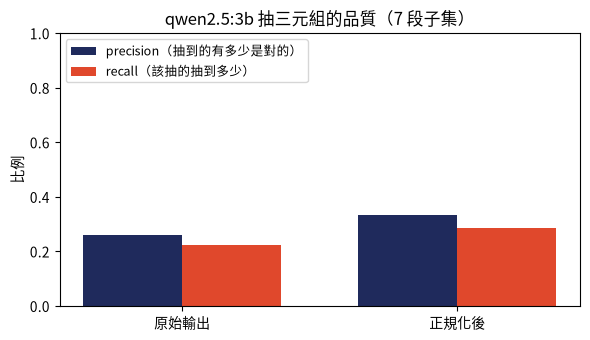

In [13]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

stages = ["原始輸出", "正規化後"]
fig, ax = plt.subplots(figsize=(6, 3.5))
x = np.arange(len(stages))
ax.bar(x - 0.18, [p0, p1], width=0.36, label="precision（抽到的有多少是對的）", color="#1f2a5c")
ax.bar(x + 0.18, [r0, r1], width=0.36, label="recall（該抽的抽到多少）", color="#e0482c")
ax.set_xticks(x, stages)
ax.set_ylim(0, 1)
ax.set_ylabel("比例")
ax.set_title(f"qwen2.5:3b 抽三元組的品質（{len(SUBSET)} 段子集）")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

正規化只動名字，不會讓錯的關係變對，所以 precision 的提升有上限。
剩下的錯（方向反、關係標錯、客體不是實體）要靠更好的模型、更細的 prompt，或人工校對。

## Step 10：人工校對，載入全量，存檔

後面三本 notebook 要比較「圖檢索 vs 向量檢索」，圖本身不能有錯，否則比的是抽取品質而不是檢索方式。
所以最後一步模擬「離線批次抽取＋人工校對」的成果：

- 子集 7 段：模型抽對的標 `source: "llm"`，模型漏掉、由人補上的標 `source: "manual"`，模型抽錯的丟掉
- 其他 27 段：假設已經離線抽完並校對過，直接載入 `gold_triples.json`，標 `source: "reviewed"`

課堂上用 `gold_triples.json` 代替人工審查；真實專案裡，這一步是抽樣檢查加上 Step 8 的衝突清單。
全量三元組也要過一次 Step 7 的別名表：標準答案裡同時出現了「羅傑」和「哥爾·D·羅傑」，不合併的話圖上會有兩個羅傑。
另外，同一件事常在好幾段都提到（騙人布的夢想出現在 3 段），標準答案每段各記一次；建圖時只留一條，不然圖上會有重複的邊。

In [14]:
from collections import Counter

final, seen = [], set()
for g in gold_all:
    t = normalize(g)
    key = (t["subject"], t["relation"], t["object"])
    if key in seen:  # 同一件事在好幾段都提到，只留第一次出現的那條
        continue
    seen.add(key)
    if g["paragraph"] in SUBSET:
        source = "llm" if any(same(n, g) for n in normalized) else "manual"
    else:
        source = "reviewed"
    final.append({**t, "source": source})
rejected = [t for t in normalized if not any(same(t, g) for g in gold)]

print(f"標準答案 {len(gold_all)} 條，去掉重複後 {len(final)} 條：", dict(Counter(t["source"] for t in final)))
print(f"丟掉 {len(rejected)} 條錯誤，例如：")
for t in rejected[:8]:
    print("  ", t["subject"], t["relation"], t["object"])

標準答案 210 條，去掉重複後 182 條： {'manual': 34, 'reviewed': 134, 'llm': 14}
丟掉 28 條錯誤，例如：
   魯夫 FROM 東海
   魯夫 MEMBER_OF 風車村
   魯夫 HAS_FATHER 多拉格
   魯夫 CAPTAIN_OF 風車村
   魯夫 DREAMS_OF 揚帆出海
   亞爾薇達 MEMBER_OF 海賊
   科比 MEMBER_OF 海賊
   科比 MEMBER_OF 海軍


被丟掉的不一定都是錯的：「魯夫的父親是多拉格」原文第 1 段有寫，只是標準答案沒標。
標準答案也是人做的，也會漏；真實專案裡，校對者看到這種「模型抽到、答案沒有」的邊，要回原文確認後補進標準答案。

最後把節點也整理出來：每個節點有名字、類型（之後當 Neo4j 的標籤）和別名。
別名在下一本做「問題裡提到了誰」的比對時會用到。

類型先看「當客體時的關係」（`MEMBER_OF` 的客體一定是海賊團），沒當過客體的主體才預設是人物；
這樣「巴托俱樂部」雖然當過主體，仍然是海賊團。

In [15]:
node_types = {}
for t in final:
    node_types.setdefault(t["object"], RANGE[t["relation"]])
for t in final:
    node_types.setdefault(t["subject"], "Person")

nodes = [{"name": n, "label": lbl, "aliases": ALIASES.get(n, [])} for n, lbl in sorted(node_types.items())]
out = {"nodes": nodes, "triples": final}
Path("data/triples.json").write_text(json.dumps(out, ensure_ascii=False, indent=1), encoding="utf-8")

print(len(nodes), "個節點：", Counter(n["label"] for n in nodes))
print(Counter(t["relation"] for t in out["triples"]))

187 個節點： Counter({'Person': 88, 'Treasure': 46, 'Crew': 31, 'Place': 14, 'Dream': 8})
Counter({'OWNS': 50, 'MEMBER_OF': 37, 'CAPTAIN_OF': 28, 'DEFEATED': 25, 'FROM': 18, 'HAS_FATHER': 10, 'DREAMS_OF': 8, 'BROTHER_OF': 6})


## 試試看

1. 把 `SYSTEM` 裡的範例刪掉，只留關係表，重跑 Step 5～6（記得先清空 `cache`）。precision 和 recall 各變了多少？
2. 在 Step 7 加上「LLM 裁決」：把一對候選名字和兩段原文丟給模型，問它「是不是同一個人」，只回答是或否。它能認出「草帽小子 = 魯夫」嗎？
3. 把 `max_tokens` 改成 100，看看長段落會發生什麼事。為什麼受限輸出還是可能失敗？

## 小結

- 抽三元組要先定規格：固定的關係清單＋每種關係的主客體類型，用 Pydantic 寫成 schema 交給模型。
- 小模型抽得出大概，但方向、關係、別名都會錯；用標準答案量 precision／recall，比用眼睛抽查可靠。
- 正規化合併別名、類型衝突標出可疑的邊，最後由人拍板；名字互相包含不代表同一個東西（兩種人人果實）。
- 真實專案離線批次抽全量、人工抽樣校對。下一本用 networkx 把 `triples.json` 建成圖，做多跳查詢。